# 06 · Evaluation: full test grid, ARGO validation, ocean indicators (Phase 6)
The final model (gradient boosting + climatology feature) predicts **every ocean cell on every test day** (120 days × 11,880 cells).
It is checked against **real ARGO floats it never saw**, and used to compute oceanographic indicators.
Code: `src/oceanembed_ml/{evaluation,validation,science}/`; run `scripts/06_evaluate.py`.

In [1]:
import json, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from oceanembed_ml.config import ROOT, AUDIT, INTERIM, PROCESSED, FINAL, FIGURES, load_yaml
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
print("project root:", ROOT)

project root: D:\Ml project


## 1. Full test set (all 1.43M rows)

In [2]:
ft = json.loads((ROOT/"results"/"phase6"/"full_test_metrics.json").read_text())
print(f"rows {ft['rows']:,} | RMSE {ft['overall']['rmse']:.3f} °C | MAE {ft['overall']['mae']:.3f} | bias {ft['overall']['bias']:+.3f} | mean skill {ft['mean_skill_over_depths']:.3f}")
pd.DataFrame(ft["per_depth"]).T[["rmse","mae","bias","r2","skill_vs_clim","rmse_clim"]].round(3)

rows 1,425,600 | RMSE 0.579 °C | MAE 0.370 | bias -0.014 | mean skill 0.637


,rmse,mae,bias,r2,skill_vs_clim,rmse_clim
0,0.382,0.272,-0.010,0.958,0.723,0.724
5,0.381,0.268,-0.010,0.957,0.708,0.705
10,0.387,0.270,-0.006,0.954,0.691,0.696
20,0.432,0.295,-0.001,0.942,0.622,0.703
30,0.516,0.351,-0.012,0.917,0.542,0.761
50,0.676,0.481,-0.046,0.877,0.581,1.044
75,0.867,0.640,-0.051,0.841,0.677,1.525
100,0.980,0.739,-0.030,0.796,0.692,1.764
125,0.927,0.698,-0.013,0.794,0.691,1.668
150,0.819,0.600,-0.012,0.830,0.672,1.429


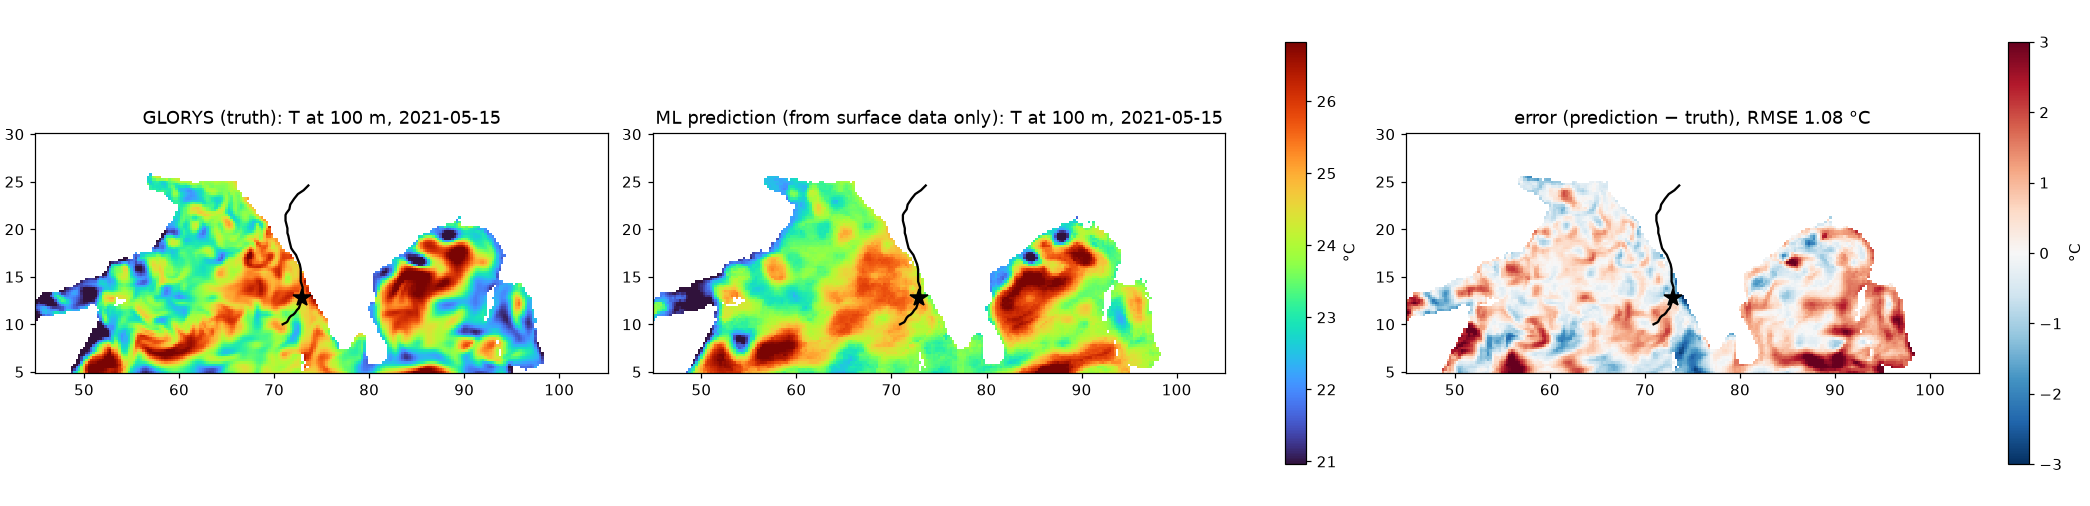

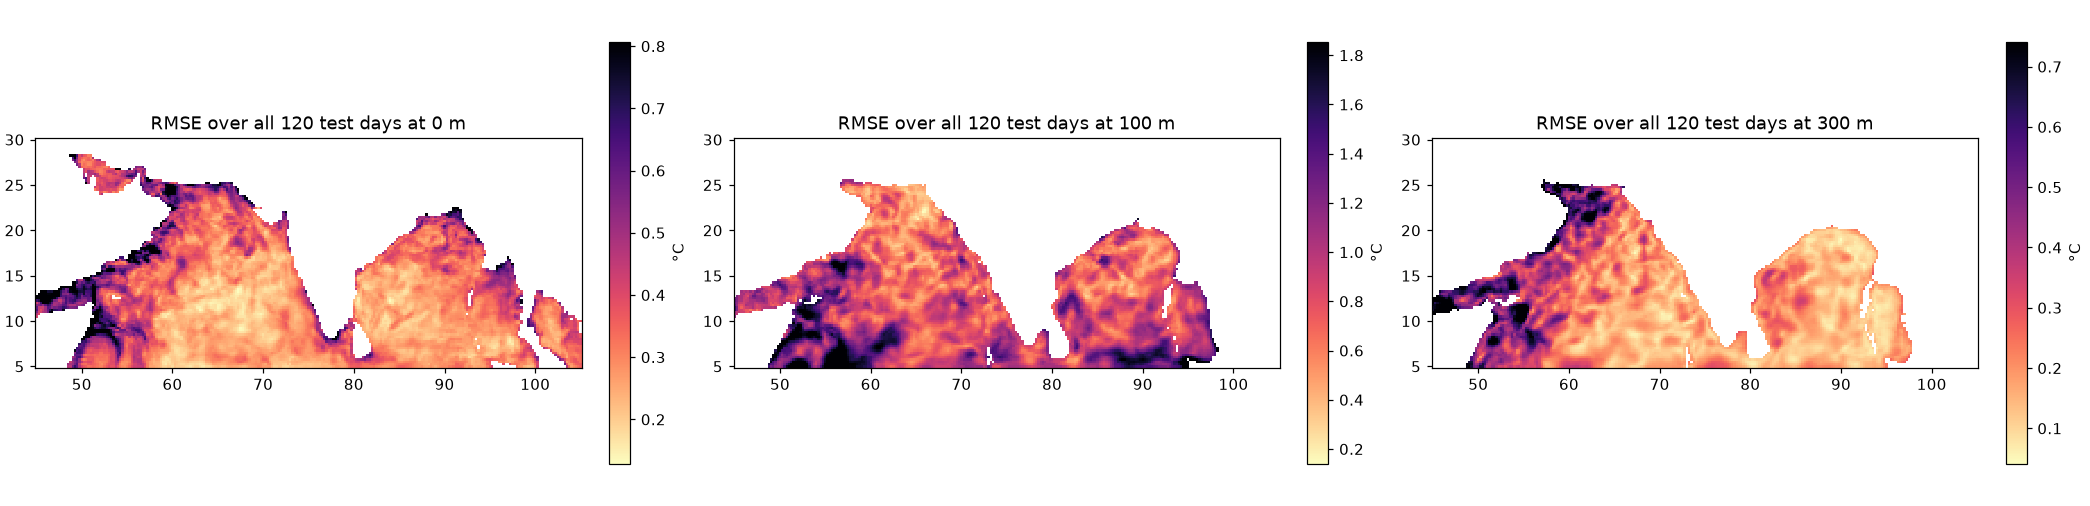

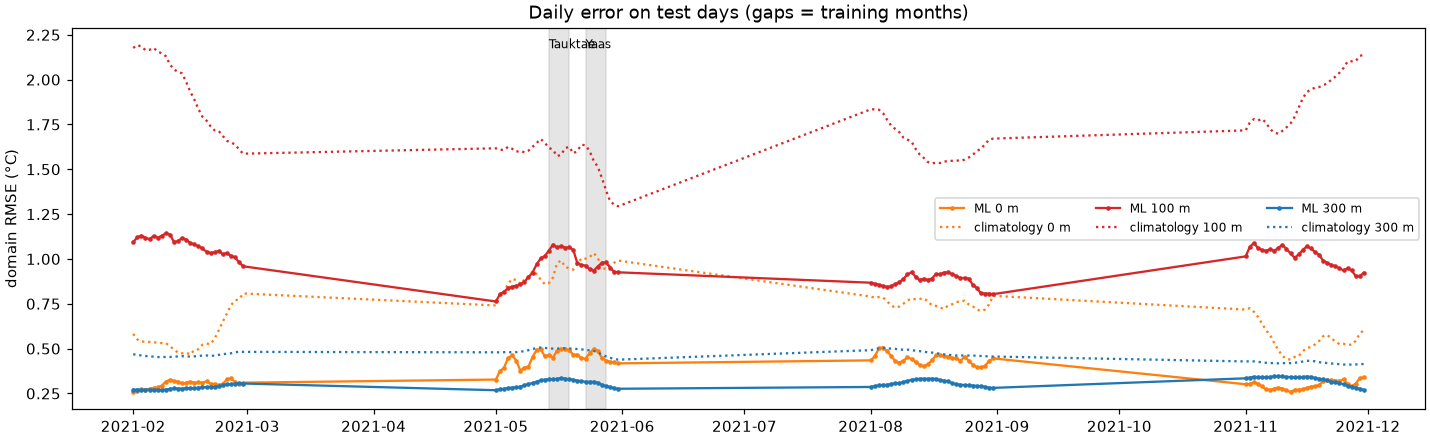

In [3]:
for f in ["01_map_T100_tauktae.png","02_map_rmse_test_period.png","07_daily_rmse.png"]:
    display(Image(filename=str(FIGURES/"phase6"/f)))

## 2. Independent validation against ARGO floats

{'n_matchups_cell_days': 1279, 'n_profiles_matched': 1282, 'n_floats': 88, 'n_delayed_mode': 1175, 'n_salinity_assumed': 363, 'by_region': {'arabian_sea': 901, 'bay_of_bengal': 311, 'other': 67}}


,n,rmse,mae,bias,r
pred,18147.0,0.718,0.472,-0.050,0.995
glorys,18145.0,0.599,0.391,0.004,0.996
clim,18147.0,1.119,0.760,-0.424,0.989


,pred,glorys,clim
0,0.380,0.402,0.761
5,0.372,0.398,0.755
10,0.380,0.394,0.754
20,0.579,0.542,0.900
30,0.720,0.644,0.947
50,0.964,0.748,1.287
75,0.942,0.801,1.473
100,0.989,0.826,1.659
125,1.044,0.845,1.741
150,0.980,0.775,1.607


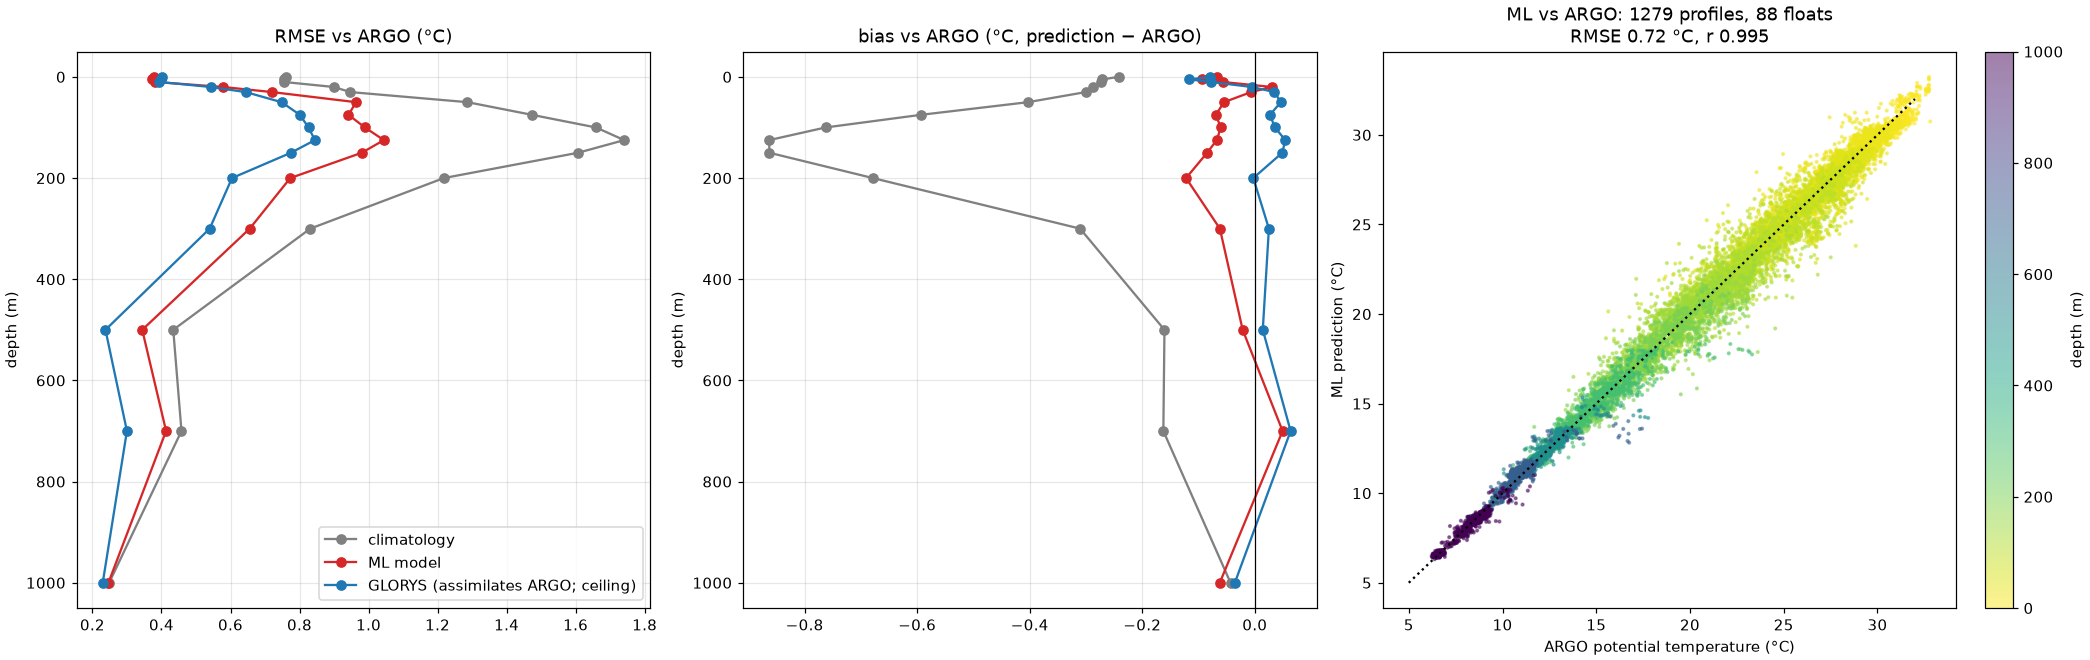

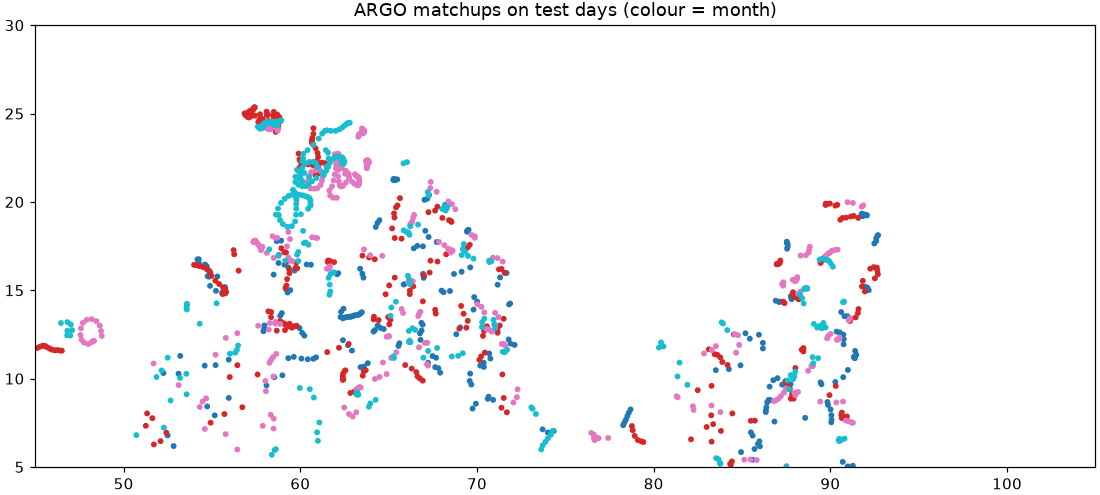

In [4]:
av = json.loads((ROOT/"results"/"phase6"/"argo_validation.json").read_text())
print({k: av[k] for k in ["n_matchups_cell_days","n_profiles_matched","n_floats","n_delayed_mode","n_salinity_assumed","by_region"]})
display(pd.DataFrame(av["overall"]).T.round(3))
display(pd.DataFrame({d: {s: v[s].get("rmse") for s in ("pred","glorys","clim")} for d, v in av["per_depth"].items()}).T.round(3))
for f in ["04_argo_validation.png","05_argo_locations.png"]:
    display(Image(filename=str(FIGURES/"phase6"/f)))

## 3. Oceanographic indicators (model vs GLORYS, climatology as baseline)

,units,ML RMSE,ML r,ML bias,clim RMSE,skill vs clim
D20,m,10.932544,0.916978,-0.361324,20.607187,0.718548
D26,m,9.934013,0.899881,-1.344478,14.932858,0.557449
TCHP,kJ cm-2,9.4755,0.966915,-1.407136,19.758379,0.770014
MLD,m,11.133235,0.873032,-2.602367,14.611609,0.419441
OHC300,GJ m-2,0.512773,0.930647,-0.018019,1.058265,0.76522


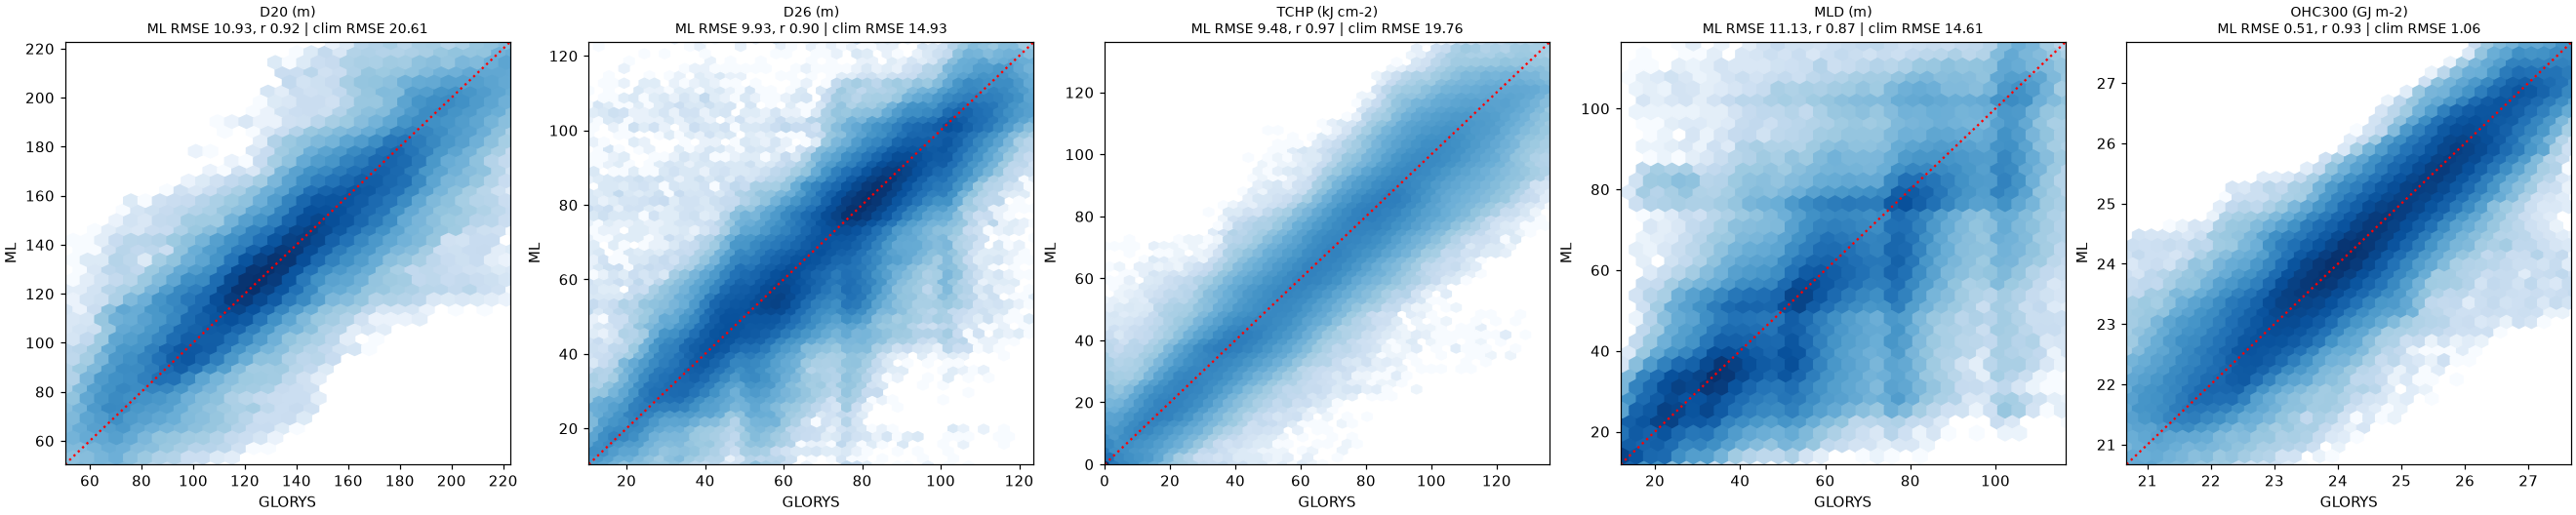

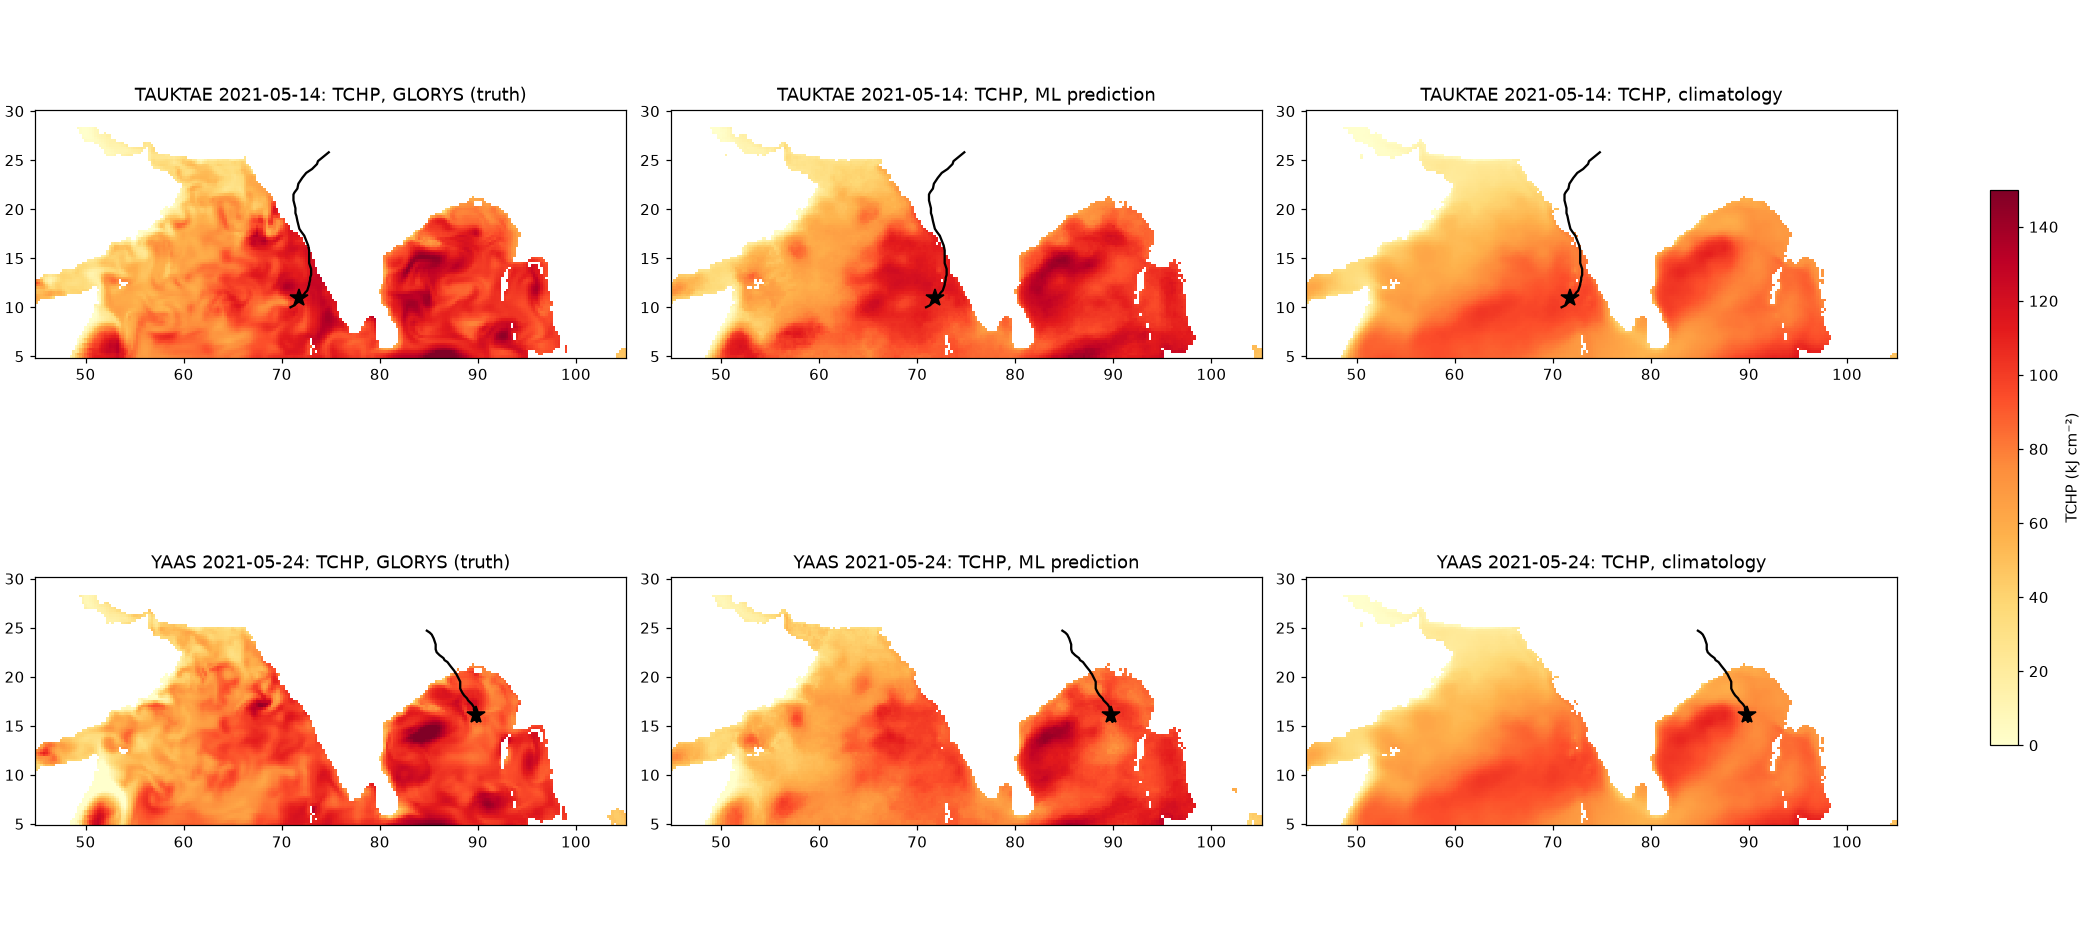

In [5]:
iv = json.loads((ROOT/"results"/"phase6"/"indicators.json").read_text())
display(pd.DataFrame({n: {"units": v["units"], "ML RMSE": v["model_vs_glorys"]["rmse"], "ML r": v["model_vs_glorys"]["r"], "ML bias": v["model_vs_glorys"]["bias"],
                          "clim RMSE": v["clim_vs_glorys"]["rmse"], "skill vs clim": v["skill_vs_clim"]} for n, v in iv.items()}).T)
for f in ["06_indicator_scatter.png","03_cyclone_tchp.png"]:
    display(Image(filename=str(FIGURES/"phase6"/f)))